In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv("crime_dataset_india.csv")
df.head()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed
0,1,02-01-2020 00:00,01-01-2020 00:00,01-01-2020 01:11,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaN
1,2,01-01-2020 19:00,01-01-2020 01:00,01-01-2020 06:26,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaN
2,3,02-01-2020 05:00,01-01-2020 02:00,01-01-2020 14:30,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaN
3,4,01-01-2020 05:00,01-01-2020 03:00,01-01-2020 14:46,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00
4,5,01-01-2020 21:00,01-01-2020 04:00,01-01-2020 16:51,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,08-01-2020 21:00


In [10]:
df.tail()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed
40155,40156,01-08-2024 16:00,07-31-2024 03:00,31-07-2024 05:05,Kolkata,312,COUNTERFEITING,78,F,Firearm,Other Crime,12,No,NaN
40156,40157,31-07-2024 14:00,07-31-2024 04:00,31-07-2024 04:14,Mumbai,300,ILLEGAL POSSESSION,75,F,NaN,Other Crime,2,Yes,29-09-2024 14:00
40157,40158,02-08-2024 03:00,07-31-2024 05:00,31-07-2024 21:33,Kanpur,423,VEHICLE - STOLEN,68,M,Other,Violent Crime,6,No,NaN
40158,40159,01-08-2024 19:00,07-31-2024 06:00,31-07-2024 11:05,Patna,311,SEXUAL ASSAULT,11,M,Blunt Object,Violent Crime,1,No,NaN
40159,40160,31-07-2024 17:00,07-31-2024 07:00,31-07-2024 17:19,Delhi,193,DOMESTIC VIOLENCE,43,F,Poison,Violent Crime,7,Yes,28-09-2024 17:00


In [4]:
print(df.shape)

(40160, 14)


In [5]:
print(df.columns)

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'City', 'Crime Code', 'Crime Description',
       'Victim Age', 'Victim Gender', 'Weapon Used', 'Crime Domain',
       'Police Deployed', 'Case Closed', 'Date Case Closed'],
      dtype='str')


In [6]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 40160
Total Columns: 14


In [7]:
summary = pd.DataFrame({
    "Metric": ["Total Rows", "Total Columns"],
    "Count": [df.shape[0], df.shape[1]]
})
display(summary)

,Metric,Count
0,Total Rows,40160
1,Total Columns,14


In [11]:
print(df.columns.tolist())

['Report Number', 'Date Reported', 'Date of Occurrence', 'Time of Occurrence', 'City', 'Crime Code', 'Crime Description', 'Victim Age', 'Victim Gender', 'Weapon Used', 'Crime Domain', 'Police Deployed', 'Case Closed', 'Date Case Closed']


In [12]:
df.isnull().sum()

Report Number             0
Date Reported             0
Date of Occurrence        0
Time of Occurrence        0
City                      0
Crime Code                0
Crime Description         0
Victim Age                0
Victim Gender             0
Weapon Used            5790
Crime Domain              0
Police Deployed           0
Case Closed               0
Date Case Closed      20098
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.dtypes

Report Number         int64
Date Reported           str
Date of Occurrence      str
Time of Occurrence      str
City                    str
Crime Code            int64
Crime Description       str
Victim Age            int64
Victim Gender           str
Weapon Used             str
Crime Domain            str
Police Deployed       int64
Case Closed             str
Date Case Closed        str
dtype: object

In [16]:
df["City"] = df["City"].str.strip()

In [17]:
df[df["Victim Age"] < 0]

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed


In [18]:

blank_counts = df.select_dtypes(include="object").apply(
    lambda col: col.astype("string").str.strip().eq("").sum()
)

print("Blank values in text columns:")
display(blank_counts[blank_counts > 0].to_frame("Blank Count"))


numeric_df = df.select_dtypes(include="number")

negative_counts = (numeric_df < 0).sum()
print("Negative values in numeric columns:")
display(negative_counts[negative_counts > 0].to_frame("Negative Count"))


for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False).head(10))

C:\Users\kumar\AppData\Local\Temp\ipykernel_31624\1822061417.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  blank_counts = df.select_dtypes(include="object").apply(


Blank values in text columns:


,Blank Count


Negative values in numeric columns:


,Negative Count



Column: Date Reported
Date Reported
05-03-2021 13:00    7
29-03-2021 22:00    7
03-01-2022 20:00    7
24-12-2023 13:00    7
15-01-2020 07:00    6
24-07-2020 16:00    6
22-09-2020 15:00    6
27-12-2020 17:00    6
04-07-2021 13:00    6
07-08-2021 22:00    6
Name: count, dtype: int64

Column: Date of Occurrence
Date of Occurrence
01-01-2020 00:00    1
01-01-2020 01:00    1
01-01-2020 02:00    1
01-01-2020 03:00    1
01-01-2020 04:00    1
01-01-2020 05:00    1
01-01-2020 06:00    1
01-01-2020 07:00    1
01-01-2020 08:00    1
01-01-2020 09:00    1
Name: count, dtype: int64

Column: Time of Occurrence
Time of Occurrence
14-10-2022 06:54    3
06-01-2020 14:55    2
13-01-2020 10:14    2
13-01-2020 20:23    2
19-01-2020 12:57    2
21-01-2020 08:40    2
24-01-2020 16:03    2
29-01-2020 22:07    2
02-02-2020 14:41    2
11-02-2020 00:43    2
Name: count, dtype: int64

Column: City
City
Delhi        5400
Mumbai       4415
Bangalore    3588
Hyderabad    2881
Kolkata      2518
Chennai      2493
Pune

C:\Users\kumar\AppData\Local\Temp\ipykernel_31624\1822061417.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


In [19]:
Q1 = df["Victim Age"].quantile(0.25)
Q3 = df["Victim Age"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Victim Age"] < lower_limit) |
    (df["Victim Age"] > upper_limit)
]

display(outliers)

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed


In [21]:
df["Date of Occurrence"] = pd.to_datetime(
    df["Date of Occurrence"], errors="coerce"
)

In [22]:
display(df[["Date of Occurrence"]].head())

,Date of Occurrence
0,2020-01-01 00:00:00
1,2020-01-01 01:00:00
2,2020-01-01 02:00:00
3,2020-01-01 03:00:00
4,2020-01-01 04:00:00


In [23]:
print(df.shape)
print(df.isnull().sum().sum())
print(df.duplicated().sum())

(40160, 14)
25888
0


In [24]:
print("Duplicate rows:", df.duplicated().sum())

print("Date of Occurrence data type:",
      df["Date of Occurrence"].dtype)

display(df.isnull().sum().to_frame("Missing Values"))

Duplicate rows: 0
Date of Occurrence data type: datetime64[us]


,Missing Values
Report Number,0
Date Reported,0
Date of Occurrence,0
Time of Occurrence,0
City,0
Crime Code,0
Crime Description,0
Victim Age,0
Victim Gender,0
Weapon Used,5790


In [25]:
display(pd.crosstab(
    df["Case Closed"],
    df["Date Case Closed"].isna(),
    margins=True
))

Date Case Closed,False,True,All
Case Closed,,,
No,0,20098,20098
Yes,20062,0,20062
All,20062,20098,40160


In [26]:

display(df["Victim Age"].describe())


negative_ages = df[df["Victim Age"] < 0]
print("Negative ages:", len(negative_ages))

zero_ages = df[df["Victim Age"] == 0]
print("Zero ages:", len(zero_ages))

high_ages = df[df["Victim Age"] > 100]
print("Ages above 100:", len(high_ages))

display(high_ages.head(10))

count    40160.00000
mean        44.49126
std         20.22555
min         10.00000
25%         27.00000
50%         44.00000
75%         62.00000
max         79.00000
Name: Victim Age, dtype: float64

Negative ages: 0
Zero ages: 0
Ages above 100: 0


,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed


In [28]:
Q1 = df["Victim Age"].quantile(0.25)
Q3 = df["Victim Age"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Victim Age"] < lower_limit) |
    (df["Victim Age"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Total outliers:", len(outliers))

display(outliers.head(10))

Q1: 27.0
Q3: 62.0
IQR: 35.0
Lower limit: -25.5
Upper limit: 114.5
Total outliers: 0


,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed


In [29]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Final dataset shape: (40160, 14)

Missing values:


,Missing Values
Report Number,0
Date Reported,0
Date of Occurrence,0
Time of Occurrence,0
City,0
Crime Code,0
Crime Description,0
Victim Age,0
Victim Gender,0
Weapon Used,5790



Duplicate rows: 0

Data types:


,Data Type
Report Number,int64
Date Reported,str
Date of Occurrence,datetime64[us]
Time of Occurrence,str
City,str
Crime Code,int64
Crime Description,str
Victim Age,int64
Victim Gender,str
Weapon Used,str


In [30]:
df["Date Reported"] = pd.to_datetime(
    df["Date Reported"], errors="coerce", dayfirst=True
)

df["Date Case Closed"] = pd.to_datetime(
    df["Date Case Closed"], errors="coerce", dayfirst=True
)

print("Date Reported:", df["Date Reported"].dtype)
print("Date of Occurrence:", df["Date of Occurrence"].dtype)
print("Date Case Closed:", df["Date Case Closed"].dtype)

Date Reported: datetime64[us]
Date of Occurrence: datetime64[us]
Date Case Closed: datetime64[us]


In [31]:
display(df[[
    "Date Reported",
    "Date of Occurrence",
    "Date Case Closed"
]].head())

,Date Reported,Date of Occurrence,Date Case Closed
0,2020-01-02 00:00:00,2020-01-01 00:00:00,NaT
1,2020-01-01 19:00:00,2020-01-01 01:00:00,NaT
2,2020-01-02 05:00:00,2020-01-01 02:00:00,NaT
3,2020-01-01 05:00:00,2020-01-01 03:00:00,2020-04-29 05:00:00
4,2020-01-01 21:00:00,2020-01-01 04:00:00,2020-01-08 21:00:00


In [32]:

date_columns = [
    "Date Reported",
    "Date of Occurrence",
    "Date Case Closed"
]

display(df[date_columns].isna().sum().to_frame("Missing Dates"))

,Missing Dates
Date Reported,0
Date of Occurrence,0
Date Case Closed,20098


In [33]:
print("Missing values:", df["Weapon Used"].isna().sum())

print("\nRecorded weapon categories:")
display(df["Weapon Used"].value_counts(dropna=False))

Missing values: 5790

Recorded weapon categories:


Weapon Used
Knife           5835
NaN             5790
Explosives      5751
Blunt Object    5737
Poison          5728
Other           5676
Firearm         5643
Name: count, dtype: int64

In [34]:
city_crimes = df["City"].value_counts()
display(city_crimes.head(10).to_frame("Total Crime Records"))

,Total Crime Records
City,
Delhi,5400
Mumbai,4415
Bangalore,3588
Hyderabad,2881
Kolkata,2518
Chennai,2493
Pune,2212
Ahmedabad,1817
Jaipur,1479


In [35]:
print(df.columns.tolist())

['Report Number', 'Date Reported', 'Date of Occurrence', 'Time of Occurrence', 'City', 'Crime Code', 'Crime Description', 'Victim Age', 'Victim Gender', 'Weapon Used', 'Crime Domain', 'Police Deployed', 'Case Closed', 'Date Case Closed']


In [36]:
print("Total records:", len(df))
print("Unique report numbers:", df["Report Number"].nunique())
print("Duplicate report numbers:", df["Report Number"].duplicated().sum())

Total records: 40160
Unique report numbers: 40160
Duplicate report numbers: 0


In [37]:
print("Earliest report date:", df["Date Reported"].min())
print("Latest report date:", df["Date Reported"].max())

display(
    df["Date Reported"]
    .dt.year.value_counts()
    .sort_index()
    .to_frame("Records by Report Year")
)

Earliest report date: 2020-01-01 05:00:00
Latest report date: 2024-08-02 18:00:00


,Records by Report Year
Date Reported,
2020,8747
2021,8766
2022,8759
2023,8761
2024,5127


In [38]:
print("Earliest occurrence:", df["Date of Occurrence"].min())
print("Latest occurrence:", df["Date of Occurrence"].max())

display(
    df["Date of Occurrence"]
    .dt.year.value_counts()
    .sort_index()
    .to_frame("Records by Occurrence Year")
)

Earliest occurrence: 2020-01-01 00:00:00
Latest occurrence: 2024-07-31 07:00:00


,Records by Occurrence Year
Date of Occurrence,
2020,8784
2021,8760
2022,8760
2023,8760
2024,5096


In [39]:
occurrence_time = pd.to_datetime(
    df["Time of Occurrence"],
    errors="coerce"
)

df["Occurrence Hour"] = occurrence_time.dt.hour

display(
    df["Occurrence Hour"]
    .value_counts()
    .sort_index()
    .to_frame("Records by Hour")
)

,Records by Hour
Occurrence Hour,
0.0,611
1.0,674
2.0,691
3.0,705
4.0,678
5.0,655
6.0,697
7.0,637
8.0,643


In [40]:
city_crimes = df["City"].value_counts()

display(
    city_crimes.head(10)
    .to_frame("Total Crime Records")
)

,Total Crime Records
City,
Delhi,5400
Mumbai,4415
Bangalore,3588
Hyderabad,2881
Kolkata,2518
Chennai,2493
Pune,2212
Ahmedabad,1817
Jaipur,1479


In [41]:
display(
    df["Crime Code"]
    .value_counts()
    .head(10)
    .to_frame("Record Count")
)

,Record Count
Crime Code,
341,108
372,108
360,108
297,103
183,102
452,102
597,101
157,101
381,101


In [42]:
display(df["Victim Age"].describe().to_frame("Victim Age Statistics"))

age_groups = pd.cut(
    df["Victim Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["Under 18", "18–30", "31–45", "46–60", "Above 60"],
    right=False
)

display(
    age_groups.value_counts()
    .sort_index()
    .to_frame("Record Count")
)

,Victim Age Statistics
count,40160.00000
mean,44.49126
std,20.22555
min,10.00000
25%,27.00000
50%,44.00000
75%,62.00000
max,79.00000


,Record Count
Victim Age,
Under 18,4526
18–30,6985
31–45,8671
46–60,8453
Above 60,11525


In [43]:
display(
    df["Victim Gender"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

,Record Count
Victim Gender,
F,22423
M,13405
X,4332


In [44]:
display(
    df["Weapon Used"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

print("Missing weapon entries:", df["Weapon Used"].isna().sum())

,Record Count
Weapon Used,
Knife,5835
NaN,5790
Explosives,5751
Blunt Object,5737
Poison,5728
Other,5676
Firearm,5643


Missing weapon entries: 5790


In [45]:
display(
    df["Crime Domain"]
    .value_counts()
    .to_frame("Record Count")
)

,Record Count
Crime Domain,
Other Crime,22948
Violent Crime,11472
Fire Accident,3825
Traffic Fatality,1915


In [46]:
display(
    df["Police Deployed"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Record Count")
)

display(df["Police Deployed"].describe().to_frame("Statistics"))

,Record Count
Police Deployed,
1,2088
2,2153
3,2119
4,2063
5,2065
6,2139
7,2057
8,2150
9,2141


,Statistics
count,40160.000000
mean,10.006250
std,5.467951
min,1.000000
25%,5.000000
50%,10.000000
75%,15.000000
max,19.000000


In [47]:
display(
    df["Case Closed"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

display(
    (df["Case Closed"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage (%)")
)

,Record Count
Case Closed,
No,20098
Yes,20062


,Percentage (%)
Case Closed,
No,50.04
Yes,49.96


In [48]:
closed_cases = df[df["Case Closed"] == "Yes"].copy()

closed_cases["Closure Duration Days"] = (
    closed_cases["Date Case Closed"] -
    closed_cases["Date Reported"]
).dt.total_seconds() / 86400

print("Closed cases:", len(closed_cases))
print("Missing closure dates:", closed_cases["Date Case Closed"].isna().sum())

display(
    closed_cases["Closure Duration Days"]
    .describe()
    .to_frame("Closure Duration Statistics")
)

Closed cases: 20062
Missing closure dates: 0


,Closure Duration Statistics
count,20062.000000
mean,88.057821
std,130.056743
min,1.000000
25%,26.000000
50%,52.000000
75%,79.000000
max,729.000000


In [49]:
display(
    df["Date of Occurrence"]
    .dt.month
    .value_counts()
    .sort_index()
    .to_frame("Records by Month Number")
)

,Records by Month Number
Date of Occurrence,
1,3720
2,3408
3,3720
4,3600
5,3720
6,3600
7,3704
8,2976
9,2880


In [50]:
display(
    df["Date of Occurrence"]
    .dt.month
    .value_counts()
    .sort_index()
    .to_frame("Records by Month Number")
)

,Records by Month Number
Date of Occurrence,
1,3720
2,3408
3,3720
4,3600
5,3720
6,3600
7,3704
8,2976
9,2880


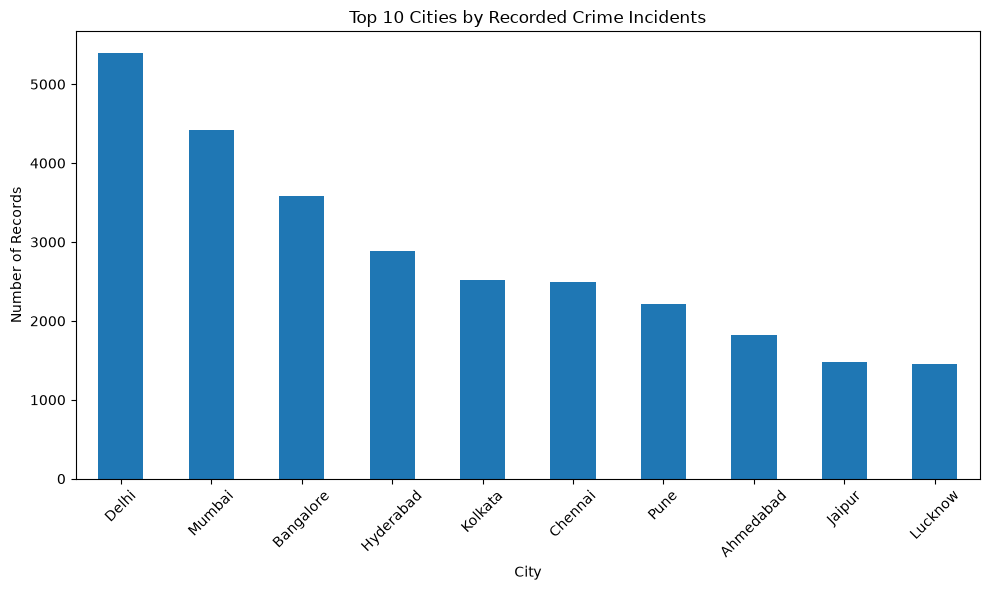

In [51]:

city_counts = df["City"].value_counts().head(10)

plt.figure(figsize=(10, 6))
city_counts.plot(kind="bar")

plt.title("Top 10 Cities by Recorded Crime Incidents")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [52]:

crime_code_counts = df["Crime Code"].value_counts().head(10)
crime_code_counts


Crime Code
341    108
372    108
360    108
297    103
183    102
452    102
597    101
157    101
381    101
563    100
Name: count, dtype: int64

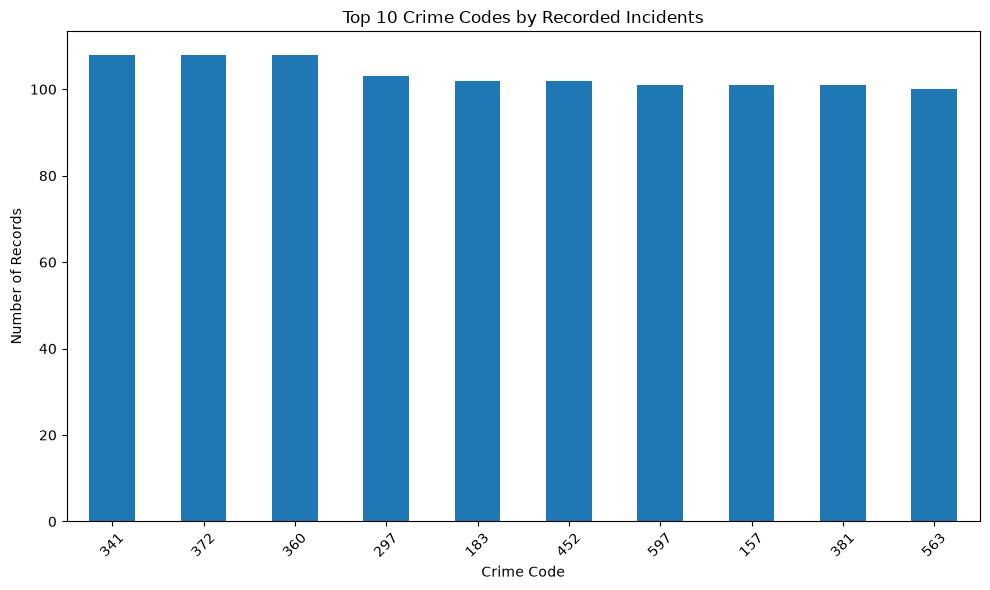

In [53]:

plt.figure(figsize=(10, 6))

crime_code_counts.plot(kind="bar")

plt.title("Top 10 Crime Codes by Recorded Incidents")
plt.xlabel("Crime Code")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


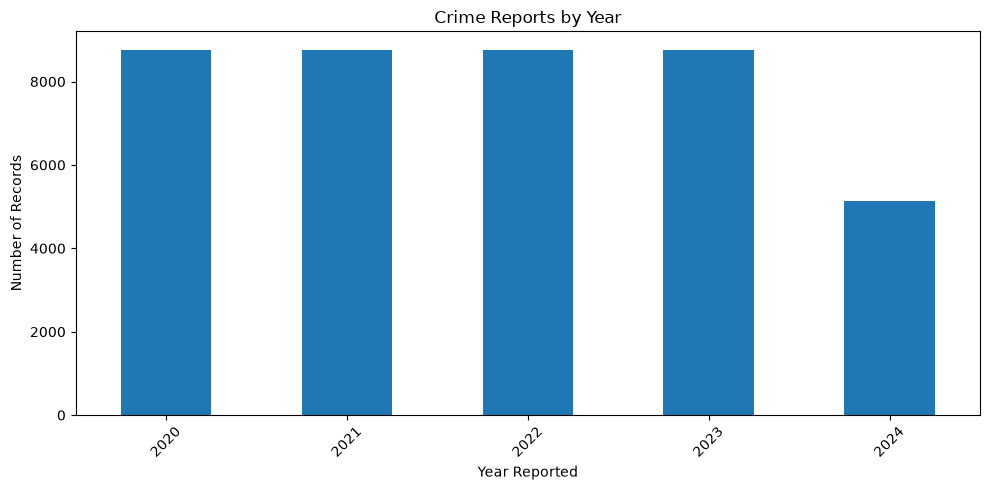

In [54]:

reported_year_counts = df["Date Reported"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 5))
reported_year_counts.plot(kind="bar")
plt.title("Crime Reports by Year")
plt.xlabel("Year Reported")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


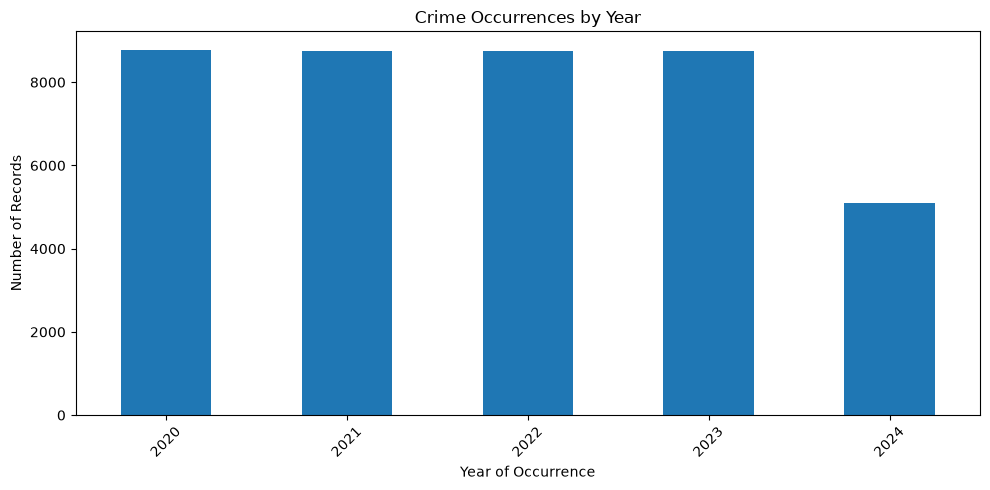

In [55]:

occurrence_year_counts = df["Date of Occurrence"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 5))
occurrence_year_counts.plot(kind="bar")
plt.title("Crime Occurrences by Year")
plt.xlabel("Year of Occurrence")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


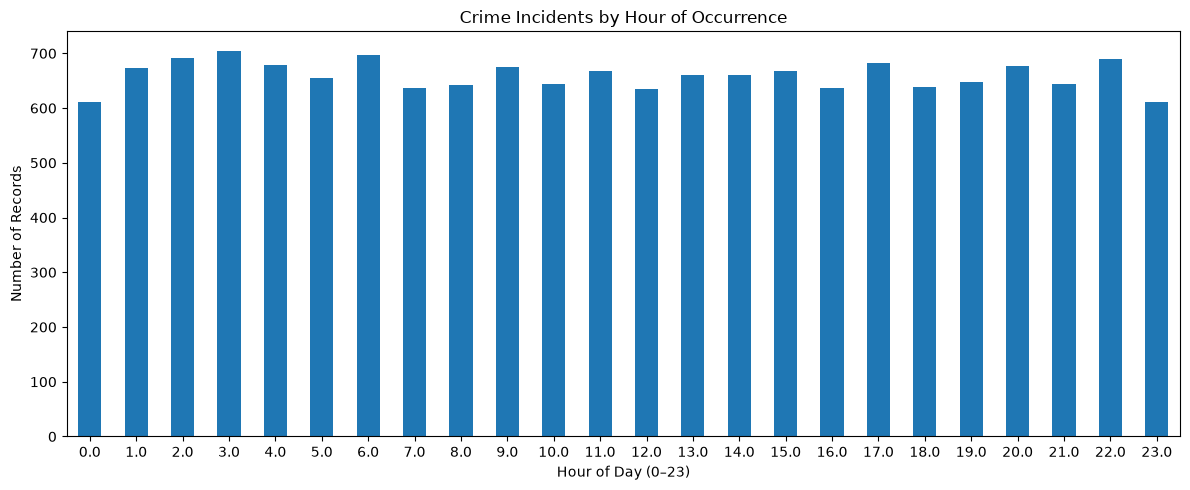

In [56]:

hour_counts = df["Occurrence Hour"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
hour_counts.plot(kind="bar")
plt.title("Crime Incidents by Hour of Occurrence")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


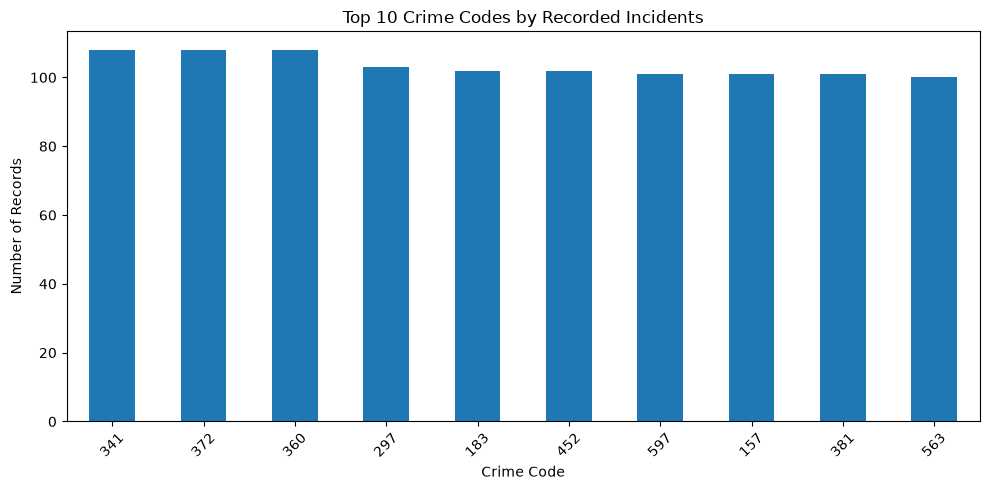

In [57]:

crime_code_counts = df["Crime Code"].value_counts().head(10)

plt.figure(figsize=(10, 5))
crime_code_counts.plot(kind="bar")
plt.title("Top 10 Crime Codes by Recorded Incidents")
plt.xlabel("Crime Code")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


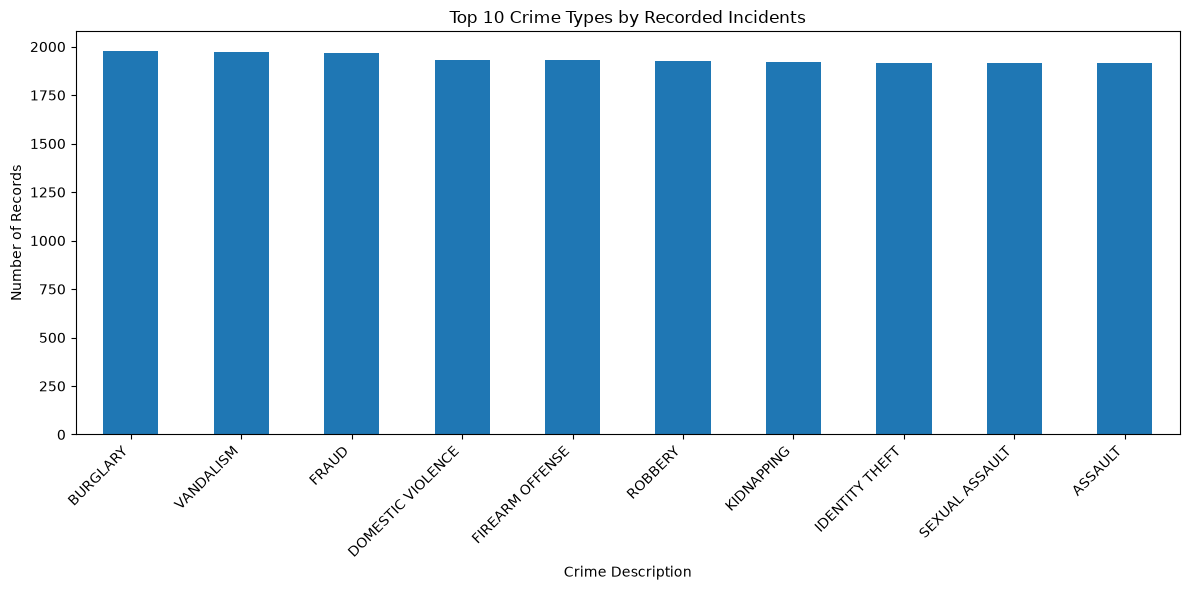

In [58]:

crime_description_counts = df["Crime Description"].value_counts().head(10)

plt.figure(figsize=(12, 6))
crime_description_counts.plot(kind="bar")
plt.title("Top 10 Crime Types by Recorded Incidents")
plt.xlabel("Crime Description")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


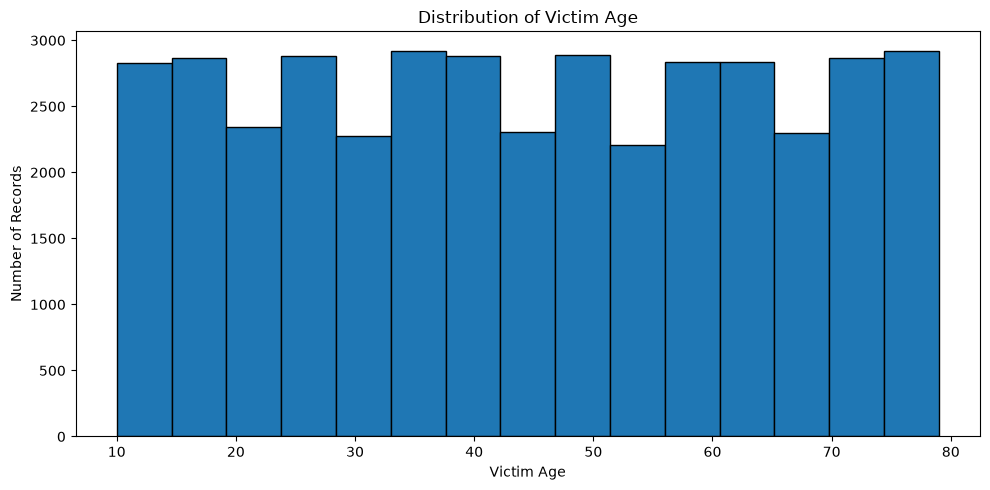

In [59]:

plt.figure(figsize=(10, 5))
df["Victim Age"].dropna().plot(kind="hist", bins=15, edgecolor="black")
plt.title("Distribution of Victim Age")
plt.xlabel("Victim Age")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


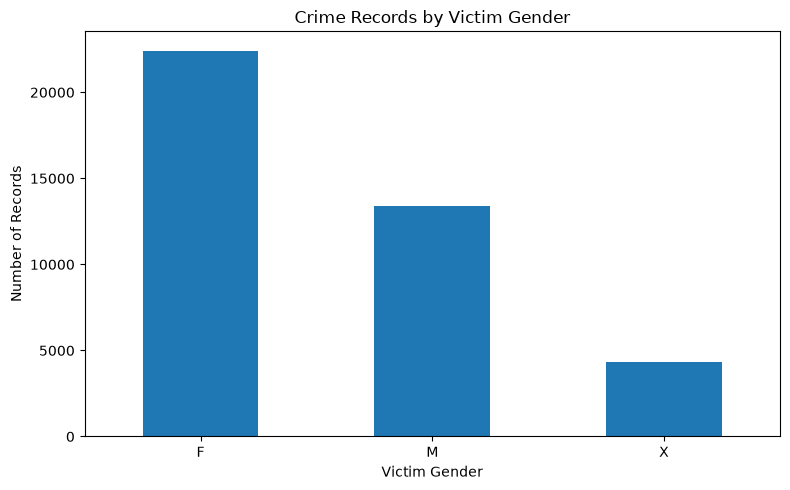

In [60]:

gender_counts = df["Victim Gender"].value_counts()

plt.figure(figsize=(8, 5))
gender_counts.plot(kind="bar")
plt.title("Crime Records by Victim Gender")
plt.xlabel("Victim Gender")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


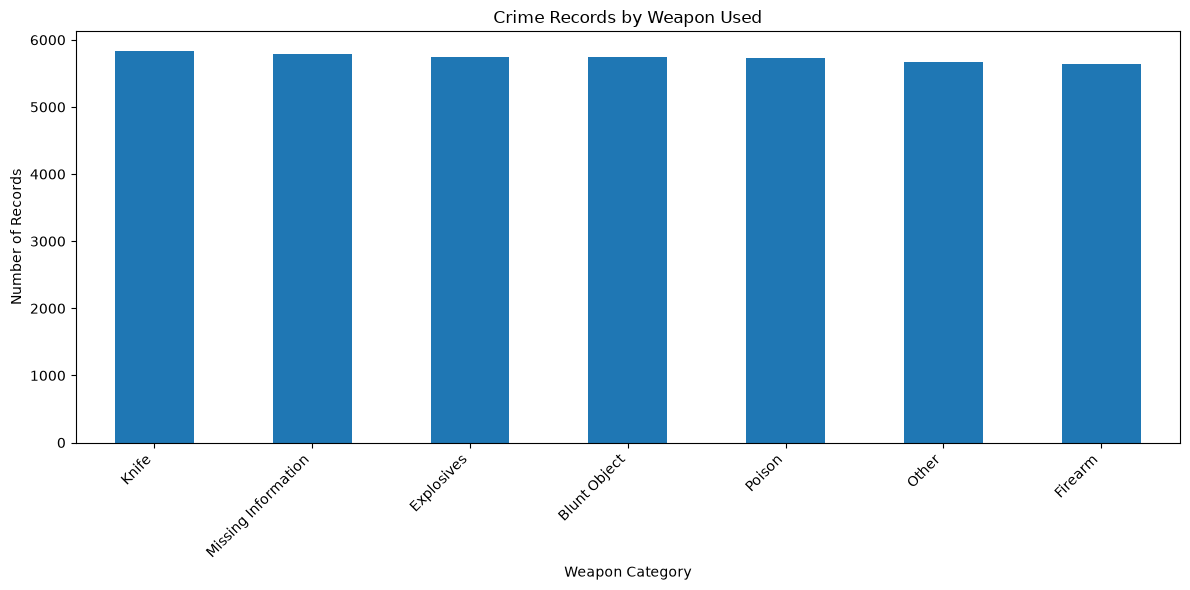

In [61]:

weapon_counts = df["Weapon Used"].fillna("Missing Information").value_counts()

plt.figure(figsize=(12, 6))
weapon_counts.plot(kind="bar")
plt.title("Crime Records by Weapon Used")
plt.xlabel("Weapon Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


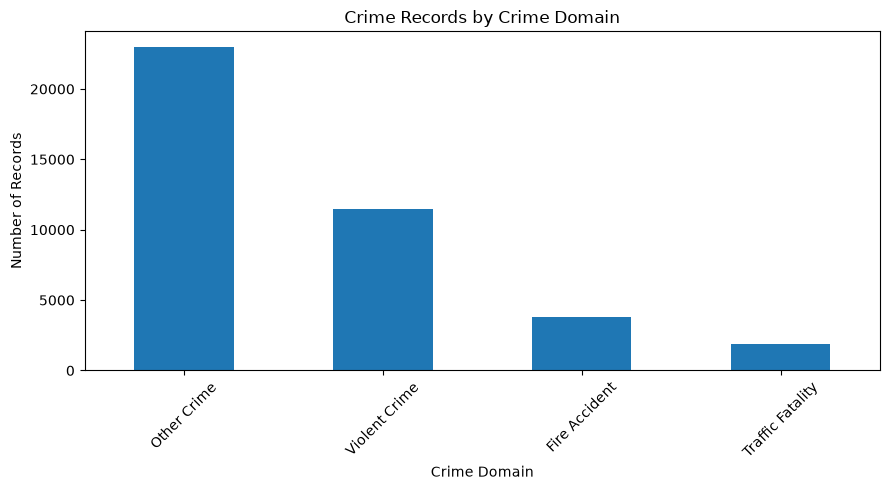

In [62]:

domain_counts = df["Crime Domain"].value_counts()

plt.figure(figsize=(9, 5))
domain_counts.plot(kind="bar")
plt.title("Crime Records by Crime Domain")
plt.xlabel("Crime Domain")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


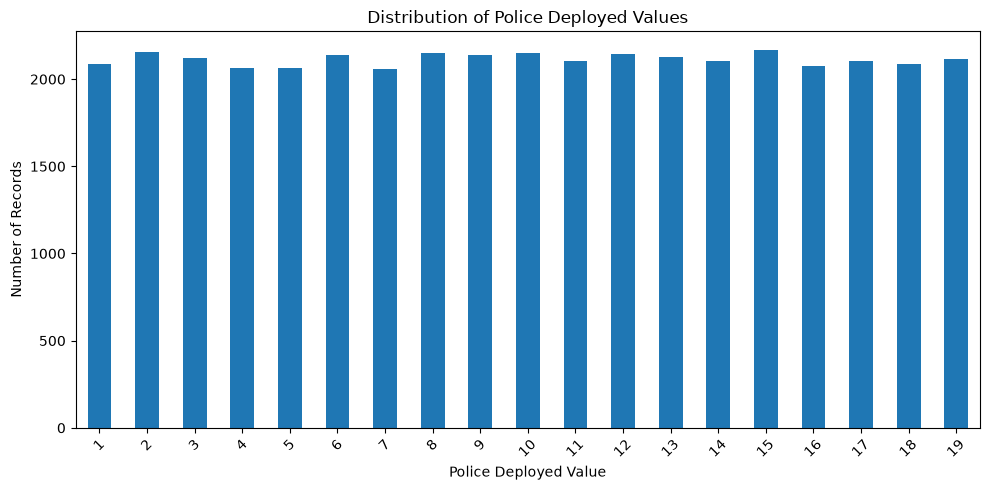

In [63]:

police_counts = df["Police Deployed"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
police_counts.plot(kind="bar")
plt.title("Distribution of Police Deployed Values")
plt.xlabel("Police Deployed Value")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


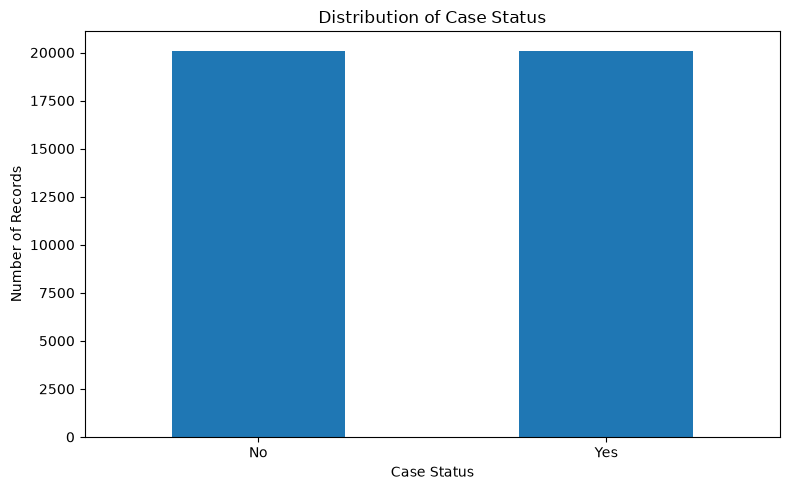

In [64]:

case_status_counts = df["Case Closed"].value_counts()

plt.figure(figsize=(8, 5))
case_status_counts.plot(kind="bar")
plt.title("Distribution of Case Status")
plt.xlabel("Case Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


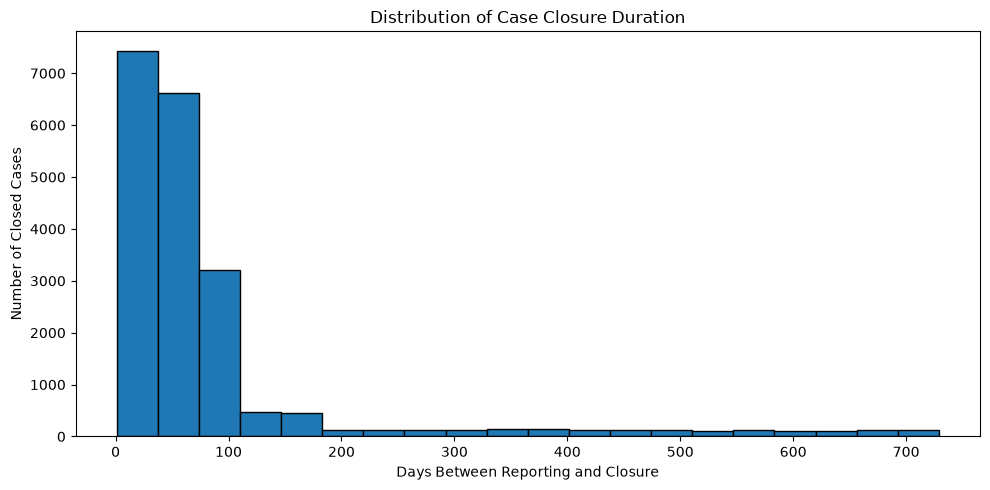

In [65]:

closed_cases = df[
    (df["Case Closed"] == "Yes") &
    (df["Date Reported"].notna()) &
    (df["Date Case Closed"].notna())
].copy()

closed_cases["Closure Duration Days"] = (
    closed_cases["Date Case Closed"] - closed_cases["Date Reported"]
).dt.total_seconds() / 86400

valid_durations = closed_cases[
    closed_cases["Closure Duration Days"] >= 0
]["Closure Duration Days"]

plt.figure(figsize=(10, 5))
valid_durations.plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Case Closure Duration")
plt.xlabel("Days Between Reporting and Closure")
plt.ylabel("Number of Closed Cases")
plt.tight_layout()
plt.show()


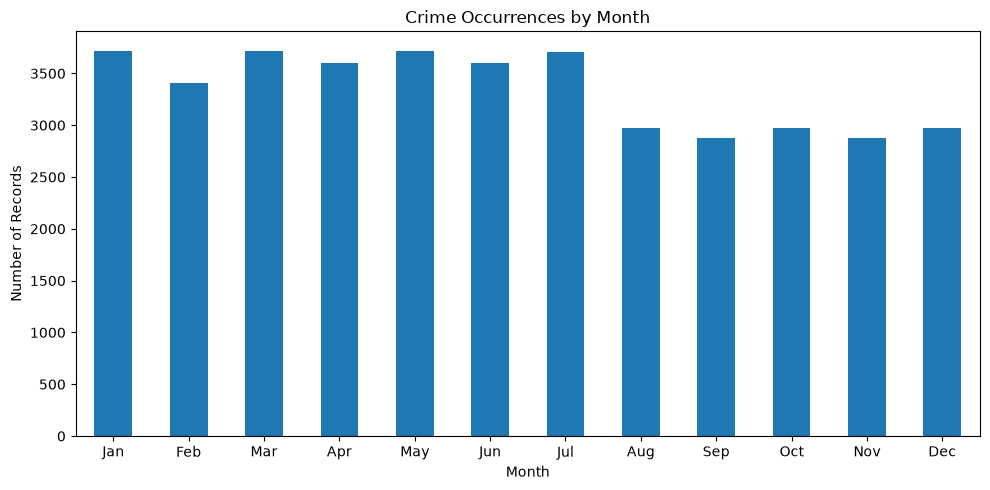

In [66]:

month_counts = (
    df["Date of Occurrence"]
    .dt.month
    .value_counts()
    .sort_index()
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

month_counts.index = month_counts.index.map(month_names)

plt.figure(figsize=(10, 5))
month_counts.plot(kind="bar")
plt.title("Crime Occurrences by Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [67]:

df["Victim Age"].describe()


count    40160.00000
mean        44.49126
std         20.22555
min         10.00000
25%         27.00000
50%         44.00000
75%         62.00000
max         79.00000
Name: Victim Age, dtype: float64

In [68]:

print("Mean Age:", df["Victim Age"].mean())
print("Median Age:", df["Victim Age"].median())
print("Mode Age:", df["Victim Age"].mode().tolist())


Mean Age: 44.49125996015936
Median Age: 44.0
Mode Age: [22, 25]


In [69]:

city_stats = df["City"].value_counts()

print("Total Cities:", df["City"].nunique())
print("Highest Records in a City:", city_stats.max())
print("Lowest Records in a City:", city_stats.min())
print("Average Records per City:", city_stats.mean())


Total Cities: 29
Highest Records in a City: 5400
Lowest Records in a City: 320
Average Records per City: 1384.8275862068965


In [70]:

gender_counts = df["Victim Gender"].value_counts(dropna=False)
gender_percentages = df["Victim Gender"].value_counts(
    normalize=True, dropna=False
) * 100

gender_summary = pd.DataFrame({
    "Count": gender_counts,
    "Percentage": gender_percentages
})

gender_summary


,Count,Percentage
Victim Gender,,
F,22423,55.834163
M,13405,33.378984
X,4332,10.786853


In [71]:

case_counts = df["Case Closed"].value_counts(dropna=False)
case_percentages = df["Case Closed"].value_counts(
    normalize=True, dropna=False
) * 100

case_summary = pd.DataFrame({
    "Count": case_counts,
    "Percentage": case_percentages
})

case_summary


,Count,Percentage
Case Closed,,
No,20098,50.044821
Yes,20062,49.955179


In [72]:

print("Valid Closed Cases:", len(valid_durations))
print("Mean Closure Duration:", valid_durations.mean())
print("Median Closure Duration:", valid_durations.median())
print("Minimum Closure Duration:", valid_durations.min())
print("Maximum Closure Duration:", valid_durations.max())
print("Standard Deviation:", valid_durations.std())


Valid Closed Cases: 20062
Mean Closure Duration: 88.05782075565746
Median Closure Duration: 52.0
Minimum Closure Duration: 1.0
Maximum Closure Duration: 729.0
Standard Deviation: 130.05674276853358


In [73]:

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary


,Missing Values,Missing Percentage
Report Number,0,0.000000
Date Reported,0,0.000000
Date of Occurrence,0,0.000000
Time of Occurrence,0,0.000000
City,0,0.000000
Crime Code,0,0.000000
Crime Description,0,0.000000
Victim Age,0,0.000000
Victim Gender,0,0.000000
Weapon Used,5790,14.417331


In [74]:

df[["Victim Age", "Police Deployed"]].dtypes

df[["Victim Age", "Police Deployed"]].describe()



,Victim Age,Police Deployed
count,40160.00000,40160.000000
mean,44.49126,10.006250
std,20.22555,5.467951
min,10.00000,1.000000
25%,27.00000,5.000000
50%,44.00000,10.000000
75%,62.00000,15.000000
max,79.00000,19.000000


In [77]:

correlation = df["Victim Age"].corr(df["Police Deployed"])

print("Correlation Coefficient:", correlation)


Correlation Coefficient: 0.003185051114078388


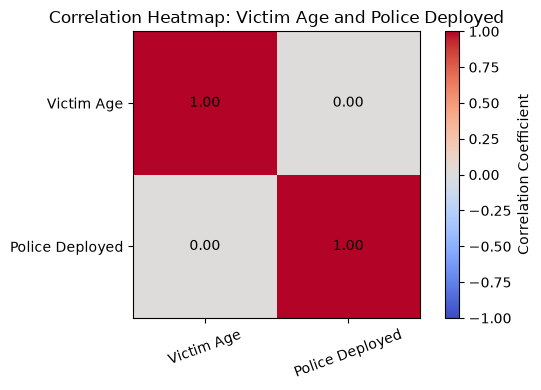

In [76]:

correlation_matrix = df[["Victim Age", "Police Deployed"]].corr()

plt.figure(figsize=(6, 4))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=20)
plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap: Victim Age and Police Deployed")
plt.tight_layout()
plt.show()


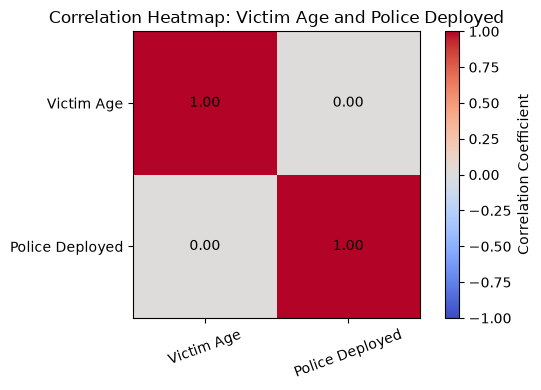

In [75]:

correlation_matrix = df[["Victim Age", "Police Deployed"]].corr()

plt.figure(figsize=(6, 4))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=20)
plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap: Victim Age and Police Deployed")
plt.tight_layout()
plt.show()
